# Lab 09 – Real-Time Object Detection (YOLO / SSD / RetinaNet) and Pose Estimation

| Task | Section |
|---|---|
| 1. YOLO on a live webcam to detect lab assets | §3 |
| 2. YOLOv3, SSD, RetinaNet on common images – boxes, labels, confidences | §4 |
| 3. Measure FPS, confidence on different object types, model size, inference time | §5 |
| 4. Discussion: real-time / small objects / CPU-only | §6 |
| 5. Real-time pose estimation from webcam (+ elbow angles) | §7 |

**Works locally (live OpenCV window, press `q` to quit) and on Google Colab (webcam snapshot via the browser).**
All models are pretrained (Ultralytics YOLO and torchvision) – no training needed.

In [1]:
# Colab already has torch/torchvision/opencv. Locally you also need: pip install torch torchvision
!pip install -q ultralytics pandas matplotlib requests tqdm

In [2]:
import os, sys, time, glob, math
import numpy as np, cv2, torch, torchvision, requests, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

IN_COLAB = 'google.colab' in sys.modules
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
YDEV = 0 if DEVICE == 'cuda' else 'cpu'            # ultralytics device argument
CONF = 0.40                                         # confidence threshold used everywhere
print('Colab:', IN_COLAB, '| device:', DEVICE)
if DEVICE == 'cpu':
    print('CPU only: this is fine, FPS will just be lower (and the CPU-vs-model comparison is more interesting).')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Colab: True | device: cuda


## 1. Helpers – drawing, webcam access (local OpenCV or Colab browser camera)

In [3]:
def color_for(label):
    rng = np.random.RandomState(abs(hash(label)) % (2**31))
    return tuple(int(c) for c in rng.randint(60, 255, 3))

def draw(img, dets, thickness=2):
    # dets: list of dict(box=[x1,y1,x2,y2], label=str, score=float). Returns a copy with boxes + 'label score'.
    out = img.copy()
    for d in dets:
        x1, y1, x2, y2 = map(int, d['box']); col = color_for(d['label'])
        cv2.rectangle(out, (x1, y1), (x2, y2), col, thickness)
        txt = f"{d['label']} {d['score']:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(out, (x1, max(0, y1-th-6)), (x1+tw+4, y1), col, -1)
        cv2.putText(out, txt, (x1+2, max(th, y1-4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return out

def colab_photo(quality=0.9):
    # Capture one webcam photo in the browser (Colab only). Returns BGR image.
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture'; div.appendChild(capture);
      const video = document.createElement('video'); video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div); div.appendChild(video);
      video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop(); div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    arr = np.frombuffer(b64decode(data.split(',')[1]), np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)

def live_demo(frame_fn, title='live', source=0, n_snapshots=3):
    # frame_fn(bgr_frame) -> annotated bgr frame.
    # Local: live OpenCV window until you press q. Colab: n_snapshots webcam photos, each annotated.
    if IN_COLAB:
        for k in range(n_snapshots):
            print(f'Snapshot {k+1}/{n_snapshots}: click Capture')
            frame = colab_photo()
            plt.figure(figsize=(8, 6)); plt.imshow(cv2.cvtColor(frame_fn(frame), cv2.COLOR_BGR2RGB))
            plt.axis('off'); plt.title(title); plt.show()
        return
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        print('Could not open the camera / video source'); return
    fps, last = 0.0, time.perf_counter()
    while True:
        ok, frame = cap.read()
        if not ok: break
        out = frame_fn(frame)
        now = time.perf_counter(); fps = 0.9*fps + 0.1/(now-last) if fps else 1/(now-last); last = now
        cv2.putText(out, f'FPS {fps:.1f}  (q = quit)', (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.imshow(title, out)
        if cv2.waitKey(1) & 0xFF == ord('q'): break
    cap.release(); cv2.destroyAllWindows()

## 2. Detector wrappers
Every model is wrapped in the same interface `predict(rgb_image, conf) -> [{box,label,score}]`, so they can be benchmarked identically.

| Model | Source | Notes |
|---|---|---|
| YOLOv8n | Ultralytics | tiny, newest, used for the live webcam task |
| YOLOv3 | Ultralytics `yolov3u.pt` | YOLOv3 backbone with Ultralytics' anchor-free head (the original Darknet weights are not distributed in a pip-friendly way) |
| SSD300-VGG16 | torchvision | classic SSD |
| SSDLite320-MobileNetV3 | torchvision | lightweight SSD for CPU / mobile |
| RetinaNet-R50-FPN | torchvision | focal-loss one-stage detector with FPN (good on small objects) |

In [4]:
from torchvision.models import detection as TVD

def sync():
    if DEVICE == 'cuda': torch.cuda.synchronize()

class YoloDet:
    def __init__(self, name, weights, imgsz=640):
        self.name, self.imgsz = name, imgsz
        self.m = YOLO(weights)
        self.params = sum(p.numel() for p in self.m.model.parameters())
    def predict(self, rgb, conf):
        r = self.m.predict(np.ascontiguousarray(rgb[:, :, ::-1]), conf=conf, imgsz=self.imgsz,
                           verbose=False, device=YDEV)[0]
        b = r.boxes
        return [dict(box=xy, label=r.names[int(c)], score=float(s))
                for xy, c, s in zip(b.xyxy.cpu().numpy(), b.cls.cpu().numpy(), b.conf.cpu().numpy())]

class TorchvisionDet:
    def __init__(self, name, builder, weights):
        self.name = name
        self.cats = weights.meta['categories']
        self.m = builder(weights=weights).eval().to(DEVICE)
        self.params = sum(p.numel() for p in self.m.parameters())
    @torch.no_grad()
    def predict(self, rgb, conf):
        x = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(DEVICE)
        o = self.m([x])[0]
        out = []
        for b, l, s in zip(o['boxes'].cpu().numpy(), o['labels'].cpu().numpy(), o['scores'].cpu().numpy()):
            if s >= conf and l < len(self.cats):
                out.append(dict(box=b, label=self.cats[l], score=float(s)))
        return out

detectors = [
    YoloDet('YOLOv8n', 'yolov8n.pt'),
    YoloDet('YOLOv3', 'yolov3u.pt'),
    TorchvisionDet('SSD300-VGG16', TVD.ssd300_vgg16, TVD.SSD300_VGG16_Weights.DEFAULT),
    TorchvisionDet('SSDLite320-MobileNetV3', TVD.ssdlite320_mobilenet_v3_large,
                   TVD.SSDLite320_MobileNet_V3_Large_Weights.DEFAULT),
    TorchvisionDet('RetinaNet-R50-FPN', TVD.retinanet_resnet50_fpn, TVD.RetinaNet_ResNet50_FPN_Weights.DEFAULT),
]
for d in detectors:
    print(f'{d.name:26s} params = {d.params/1e6:6.1f} M   fp32 size = {d.params*4/1e6:7.1f} MB')

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:02<00:00, 53.4MB/s]


Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 118MB/s]


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 74.8MB/s]


YOLOv8n                    params =    3.2 M   fp32 size =    12.6 MB
YOLOv3                     params =  103.8 M   fp32 size =   415.0 MB
SSD300-VGG16               params =   35.6 M   fp32 size =   142.6 MB
SSDLite320-MobileNetV3     params =    3.4 M   fp32 size =    13.8 MB
RetinaNet-R50-FPN          params =   34.0 M   fp32 size =   136.1 MB


## 3. Task 1 – YOLO on the live webcam: detect lab assets
YOLOv8n is pretrained on COCO, which already contains most typical lab assets (laptop, monitor=`tv`, keyboard, mouse, phone, chair, bottle, book, …).
For assets COCO does not know (e.g. a specific microcontroller board or lab equipment) set `CUSTOM_WEIGHTS` to a model you fine-tuned (snippet at the end of this section).

In [6]:
LAB_ASSETS = {'laptop', 'tv', 'keyboard', 'mouse', 'cell phone', 'chair', 'bottle', 'book', 'backpack',
              'cup', 'remote', 'clock', 'scissors', 'person', 'dining table', 'couch'}
FILTER_TO_ASSETS = True            # show only lab-asset classes
CUSTOM_WEIGHTS = None              # e.g. 'runs/detect/train/weights/best.pt' after fine-tuning on your own assets

lab_model = YOLO(CUSTOM_WEIGHTS or 'yolov8n.pt')
counts = {}

def lab_frame(frame_bgr):
    r = lab_model.predict(frame_bgr, conf=CONF, verbose=False, device=YDEV)[0]
    dets = [dict(box=xy, label=r.names[int(c)], score=float(s))
            for xy, c, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    if FILTER_TO_ASSETS and not CUSTOM_WEIGHTS:
        dets = [d for d in dets if d['label'] in LAB_ASSETS]
    for d in dets: counts[d['label']] = counts.get(d['label'], 0) + 1
    out = draw(frame_bgr, dets)
    cv2.putText(out, f'{len(dets)} lab assets', (10, out.shape[0]-12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
    return out

live_demo(lab_frame, title='YOLO – lab assets')     # local: press q to stop | Colab: click Capture
print('Detections seen per class:', counts)

Snapshot 1/3: click Capture


<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied

**(Optional) Fine-tune YOLO on your own lab assets** – photograph/label them (Roboflow / LabelImg), export in YOLO format and run:
```python
YOLO('yolov8n.pt').train(data='lab_assets/data.yaml', epochs=50, imgsz=640)
# then set CUSTOM_WEIGHTS = 'runs/detect/train/weights/best.pt' above
```

## 4. Task 2 – YOLOv3, SSD and RetinaNet on a common image set
The test set is a few COCO images plus anything you put in `my_images/` (add photos of your lab assets there; on Colab you can also take webcam snapshots below).

In [7]:
SAMPLES = {
    'bus.jpg':      'https://ultralytics.com/images/bus.jpg',
    'zidane.jpg':   'https://ultralytics.com/images/zidane.jpg',
    'cats.jpg':     'http://images.cocodataset.org/val2017/000000039769.jpg',
    'room.jpg':     'http://images.cocodataset.org/val2017/000000000139.jpg',
    'skier.jpg':    'http://images.cocodataset.org/val2017/000000000785.jpg',
    'tennis.jpg':   'http://images.cocodataset.org/val2017/000000000872.jpg',
    'street.jpg':   'http://images.cocodataset.org/val2017/000000000632.jpg',
}
os.makedirs('test_images', exist_ok=True); os.makedirs('my_images', exist_ok=True)
for fn, url in SAMPLES.items():
    p = f'test_images/{fn}'
    if not os.path.exists(p):
        try:
            open(p, 'wb').write(requests.get(url, timeout=30).content)
        except Exception as e:
            print('download failed:', fn, e)

paths = sorted(glob.glob('test_images/*.jpg') + glob.glob('my_images/*.*'))
images = {Path(p).name: cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in paths if cv2.imread(p) is not None}
print(len(images), 'images:', list(images))

7 images: ['bus.jpg', 'cats.jpg', 'room.jpg', 'skier.jpg', 'street.jpg', 'tennis.jpg', 'zidane.jpg']


In [8]:
# (Optional) add webcam snapshots of your lab to the test set.   Colab: click Capture.   Local: grabs one frame.
ADD_WEBCAM_FRAMES = 0           # set to e.g. 2 to add 2 snapshots
for k in range(ADD_WEBCAM_FRAMES):
    if IN_COLAB:
        fr = colab_photo()
    else:
        cap = cv2.VideoCapture(0); time.sleep(0.5); ok, fr = cap.read(); cap.release()
        if not ok: break
    images[f'webcam_{k}.jpg'] = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
print(len(images), 'images in the test set')

7 images in the test set


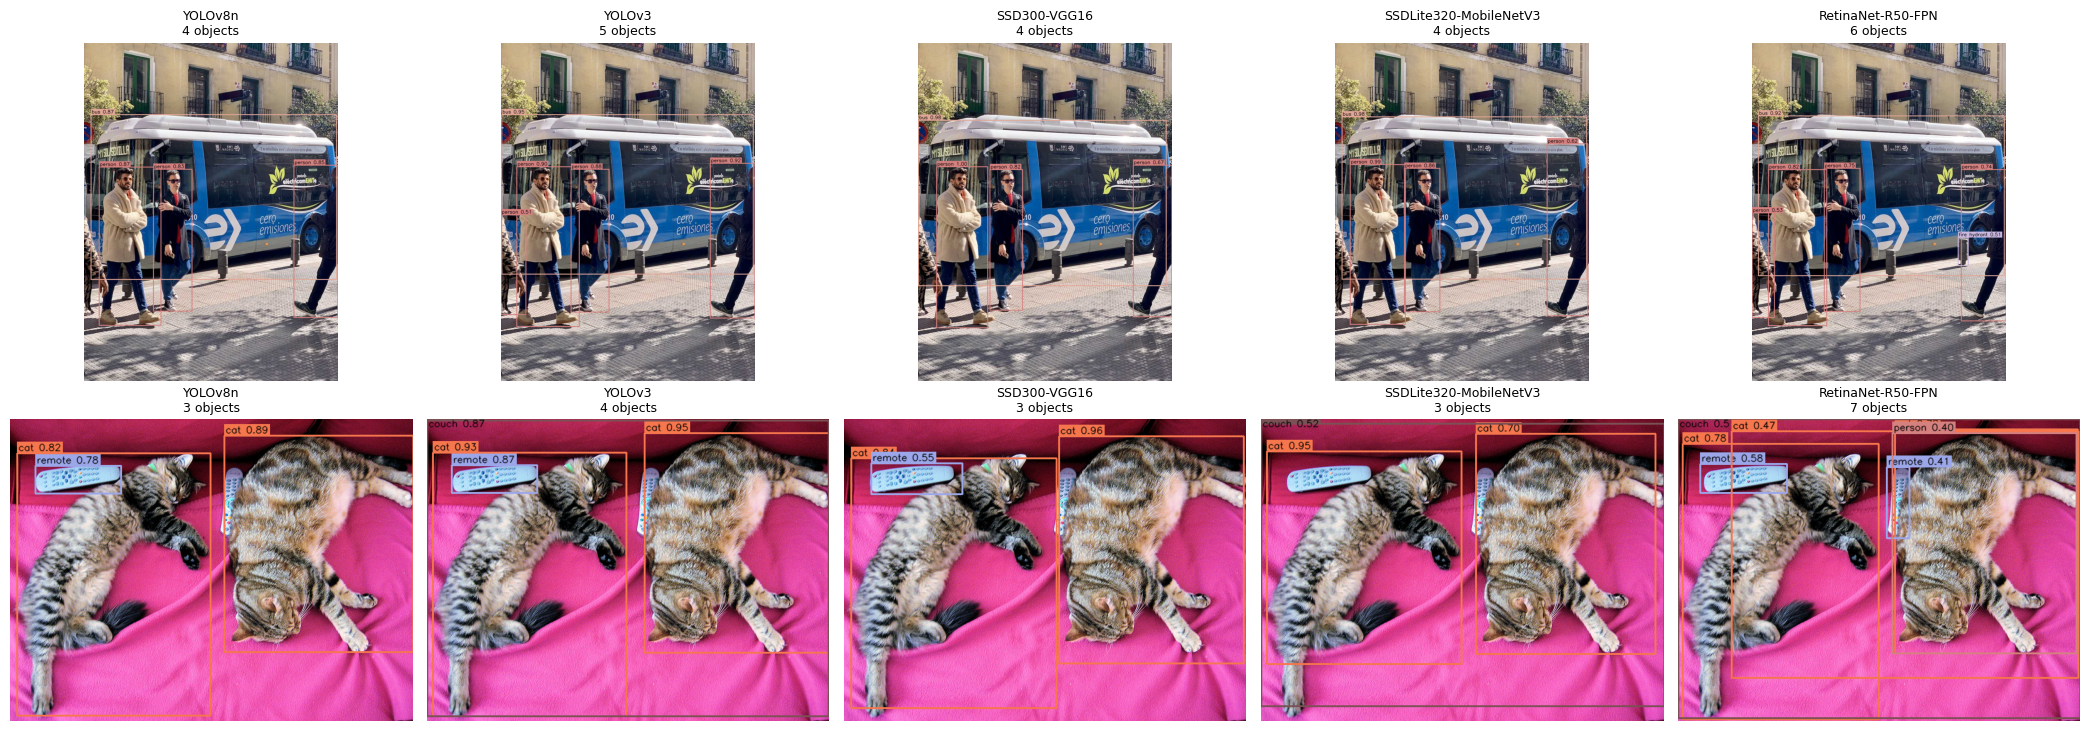

In [9]:
# Side-by-side detections (boxes + class labels + confidence scores) for every model on 2 images
show = list(images)[:2]
fig, axs = plt.subplots(len(show), len(detectors), figsize=(4.2*len(detectors), 3.8*len(show)))
axs = np.atleast_2d(axs)
for r, name in enumerate(show):
    for c, det in enumerate(detectors):
        dets = det.predict(images[name], CONF)
        axs[r, c].imshow(draw(images[name], dets)); axs[r, c].axis('off')
        axs[r, c].set_title(f'{det.name}\n{len(dets)} objects', fontsize=9)
plt.tight_layout(); plt.show()

## 5. Task 3 – Measure: FPS, inference time, model size, confidence per object type
* **Inference time / FPS** – mean time of `predict()` per frame (2 warm-up runs excluded, GPU synchronised).
* **Model size** – parameter count and fp32 size in MB.
* **Confidence on different object types** – mean score per class and per object *size* (COCO definition: small < 32², medium < 96², large ≥ 96² pixels).
  Without ground-truth labels, confidence and detection counts are the proxy for accuracy.

In [10]:
def benchmark(det, imgs, conf, warmup=2):
    for _ in range(warmup): det.predict(imgs[0], conf)
    times, dets = [], []
    for im in imgs:
        sync(); t = time.perf_counter()
        d = det.predict(im, conf)
        sync(); times.append(time.perf_counter() - t); dets.append(d)
    return np.array(times), dets

def size_bucket(box):
    a = (box[2]-box[0]) * (box[3]-box[1])
    return 'small' if a < 32**2 else 'medium' if a < 96**2 else 'large'

imgs = list(images.values()); names = list(images)
rows, det_rows = [], []
for det in detectors:
    t, dets = benchmark(det, imgs, CONF)
    for n, dl in zip(names, dets):
        for d in dl:
            det_rows.append(dict(model=det.name, image=n, label=d['label'], score=d['score'], size=size_bucket(d['box'])))
    df_m = pd.DataFrame([r for r in det_rows if r['model'] == det.name])
    row = {'model': det.name, 'params (M)': det.params/1e6, 'size fp32 (MB)': det.params*4/1e6,
           'ms / frame': t.mean()*1000, 'p95 ms': np.percentile(t, 95)*1000, 'FPS': 1/t.mean(),
           'detections': len(df_m), 'mean conf': df_m.score.mean() if len(df_m) else np.nan}
    for s in ('small', 'medium', 'large'):
        sub = df_m[df_m['size'] == s] if len(df_m) else df_m
        row[f'{s} #'] = len(sub); row[f'{s} conf'] = sub.score.mean() if len(sub) else np.nan
    rows.append(row)

results = pd.DataFrame(rows).set_index('model')
det_df = pd.DataFrame(det_rows)
results.round(3)

,params (M),size fp32 (MB),ms / frame,p95 ms,FPS,detections,mean conf,small #,small conf,medium #,medium conf,large #,large conf
model,,,,,,,,,,,,,
YOLOv8n,3.157,12.629,18.983,24.351,52.679,22,0.768,1,0.603,7,0.661,14,0.834
YOLOv3,103.754,415.017,65.968,76.181,15.159,36,0.761,5,0.561,13,0.727,18,0.841
SSD300-VGG16,35.642,142.567,38.839,41.670,25.748,20,0.833,0,NaN,6,0.664,14,0.906
SSDLite320-MobileNetV3,3.440,13.760,36.499,40.653,27.398,20,0.791,2,0.575,2,0.887,16,0.806
RetinaNet-R50-FPN,34.015,136.060,139.345,151.274,7.176,43,0.655,6,0.577,16,0.590,21,0.727


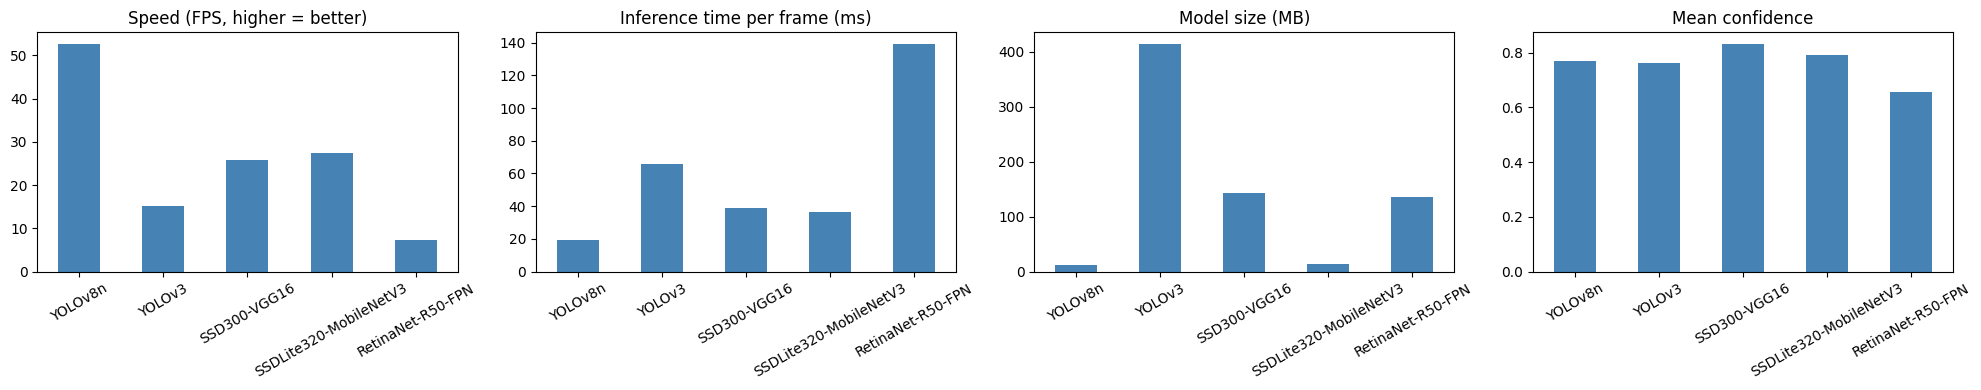

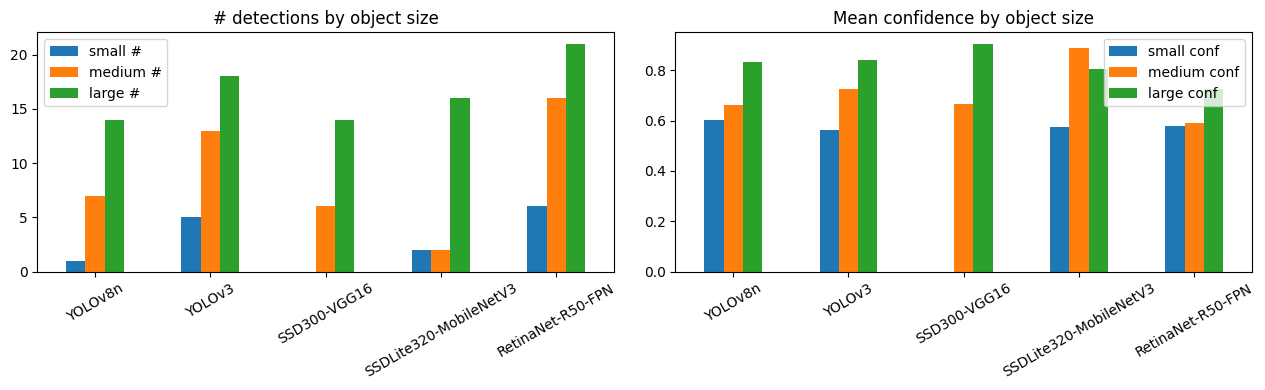

model,RetinaNet-R50-FPN,SSD300-VGG16,SSDLite320-MobileNetV3,YOLOv3,YOLOv8n
label,,,,,
bed,0.78,0.88,0.94,0.95,0.91
bottle,0.68,NaN,NaN,0.53,0.60
bus,0.92,0.98,0.98,0.95,0.87
cat,0.67,0.90,0.82,0.94,0.86
chair,0.60,0.77,0.89,0.82,0.65
person,0.76,0.90,0.83,0.85,0.82
potted plant,0.69,0.63,0.85,0.72,0.69
remote,0.50,0.55,NaN,0.87,0.78
tv,0.86,0.85,0.83,0.75,0.93


In [11]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
for ax, col, title in zip(axs, ['FPS', 'ms / frame', 'size fp32 (MB)', 'mean conf'],
                          ['Speed (FPS, higher = better)', 'Inference time per frame (ms)', 'Model size (MB)', 'Mean confidence']):
    results[col].plot.bar(ax=ax, color='steelblue'); ax.set_title(title); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

# detections / confidence by object size
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
results[['small #', 'medium #', 'large #']].plot.bar(ax=axs[0]); axs[0].set_title('# detections by object size')
results[['small conf', 'medium conf', 'large conf']].plot.bar(ax=axs[1]); axs[1].set_title('Mean confidence by object size')
for a in axs: a.tick_params(axis='x', rotation=30); a.set_xlabel('')
plt.tight_layout(); plt.show()

# confidence per object class (top 10 most-detected classes)
top = det_df.label.value_counts().head(10).index
display(det_df[det_df.label.isin(top)].pivot_table(index='label', columns='model', values='score', aggfunc='mean').round(2))

## 6. Task 4 – Which model is best for…?

In [12]:
r = results
best = lambda col, fn: fn(r[col].dropna()) if r[col].notna().any() else None
print('Real-time detection        -> highest FPS          :', r['FPS'].idxmax(), f"({r['FPS'].max():.1f} FPS)")
print('Small object recognition   -> most small detections:', r['small #'].idxmax(),
      f"({int(r['small #'].max())} detections, mean conf {r.loc[r['small #'].idxmax(), 'small conf']:.2f})")
print('Resource-limited / CPU-only-> smallest model       :', r['size fp32 (MB)'].idxmin(),
      f"({r['size fp32 (MB)'].min():.1f} MB, {r.loc[r['size fp32 (MB)'].idxmin(), 'ms / frame']:.0f} ms/frame)")
print('Highest mean confidence                            :', r['mean conf'].idxmax(), f"({r['mean conf'].max():.2f})")
print('\nSpeed/accuracy trade-off (FPS x mean conf):')
print((r['FPS'] * r['mean conf']).sort_values(ascending=False).round(2))

Real-time detection        -> highest FPS          : YOLOv8n (52.7 FPS)
Small object recognition   -> most small detections: RetinaNet-R50-FPN (6 detections, mean conf 0.58)
Resource-limited / CPU-only-> smallest model       : YOLOv8n (12.6 MB, 19 ms/frame)
Highest mean confidence                            : SSD300-VGG16 (0.83)

Speed/accuracy trade-off (FPS x mean conf):
model
YOLOv8n                   40.48
SSDLite320-MobileNetV3    21.67
SSD300-VGG16              21.45
YOLOv3                    11.53
RetinaNet-R50-FPN          4.70
dtype: float64


### Discussion (confirm each point against *your* table above – numbers depend on your hardware)

**Real-time detection.** The lightweight single-stage models win: **YOLOv8n** (and **SSDLite-MobileNetV3** on CPU) reach tens of FPS because they use one forward pass with small backbones. YOLOv3 (Darknet-53) and RetinaNet (ResNet-50 + FPN) are noticeably slower, and SSD300-VGG16 is heavy because of the VGG backbone, even though its 300×300 input is small.

**Small-object recognition.** Models that keep high-resolution, multi-scale features do best: **RetinaNet (FPN)** and **YOLO** (640 px input, 3 detection scales). SSD300 and SSDLite320 downscale the image to 300/320 px, so small objects shrink to a few pixels and are often missed – check the *small #* / *small conf* columns.

**Resource-limited / CPU-only systems.** Choose the smallest model: **SSDLite320-MobileNetV3** (≈3 M params) or **YOLOv8n** (≈3 M params). RetinaNet and SSD300-VGG16 (>30 M params) and YOLOv3 (≈60 M) are too heavy without a GPU.

**Overall.** YOLOv8n gives the best accuracy/speed trade-off for live webcam use; RetinaNet is preferable when accuracy on small or crowded objects matters more than frame rate; SSDLite is the pick for embedded/CPU deployments.

## 7. Task 5 – Real-time pose estimation from the webcam
**Model:** `yolov8n-pose` (17 COCO keypoints per person, single forward pass → real-time).
Each frame: detect people → draw skeleton → compute **elbow angles** (shoulder–elbow–wrist) → overlay the live joint coordinates.

In [13]:
pose_model = YOLO('yolov8n-pose.pt')
KP = ['nose', 'l_eye', 'r_eye', 'l_ear', 'r_ear', 'l_shoulder', 'r_shoulder', 'l_elbow', 'r_elbow',
      'l_wrist', 'r_wrist', 'l_hip', 'r_hip', 'l_knee', 'r_knee', 'l_ankle', 'r_ankle']
SKELETON = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12),
            (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]
KP_CONF = 0.5

def joint_angle(a, b, c):
    # angle (degrees) at point b formed by a-b-c
    ba, bc = np.asarray(a) - np.asarray(b), np.asarray(c) - np.asarray(b)
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    return math.degrees(math.acos(np.clip(cos, -1, 1)))

last_coords = {}

def pose_frame(frame_bgr, verbose_coords=True):
    r = pose_model.predict(frame_bgr, conf=0.4, verbose=False, device=YDEV)[0]
    out = frame_bgr.copy()
    if r.keypoints is None or len(r.keypoints.xy) == 0:
        return out
    xy = r.keypoints.xy.cpu().numpy(); cf = r.keypoints.conf.cpu().numpy()
    for p in range(len(xy)):
        k, c = xy[p], cf[p]
        for a, b in SKELETON:                                   # skeleton (bones)
            if c[a] > KP_CONF and c[b] > KP_CONF:
                cv2.line(out, tuple(k[a].astype(int)), tuple(k[b].astype(int)), (0, 255, 0), 3)
        for i in range(17):                                     # joints
            if c[i] > KP_CONF: cv2.circle(out, tuple(k[i].astype(int)), 5, (0, 0, 255), -1)
        for name, (s, e, w) in {'L': (5, 7, 9), 'R': (6, 8, 10)}.items():   # elbow angles
            if min(c[s], c[e], c[w]) > KP_CONF:
                ang = joint_angle(k[s], k[e], k[w])
                cv2.putText(out, f'{ang:.0f}', tuple((k[e] + [8, -8]).astype(int)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
                last_coords[f'person{p}_{name}_elbow_angle'] = round(ang, 1)
        if p == 0:                                              # live coordinates panel for person 0
            for j, name in enumerate(['nose', 'l_wrist', 'r_wrist']):
                i = KP.index(name)
                if c[i] > KP_CONF:
                    txt = f'{name}: ({k[i][0]:.0f}, {k[i][1]:.0f})'
                    cv2.putText(out, txt, (10, 55 + 22*j), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
                    last_coords[name] = (round(float(k[i][0]), 1), round(float(k[i][1]), 1))
    return out

live_demo(pose_frame, title='Pose estimation', n_snapshots=3)     # local: press q to stop
print('Last coordinates / angles:', last_coords)

Snapshot 1/3: click Capture


<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied

**Expected output:** live video with the green skeleton and red joints, the elbow angles (yellow numbers at each elbow) and the nose / wrist coordinates updating every frame.
Tip: bend your arm in front of the camera – the elbow angle goes from ≈180° (straight) to ≈40° (fully bent).